# 01 · Sesgo–varianza, validación y fugas de información

**Objetivo:** entender qué estima la validación cruzada, cuánto varía esa estimación y las dos
formas más comunes de engañarse: **fugas** (el preprocesamiento ve datos de test) y
**optimismo de selección** (reportar el mejor de muchos puntajes ruidosos).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

## 1. Descomposición sesgo–varianza por simulación

Error esperado en un punto $x$: $\mathbb{E}[(y - \hat f(x))^2] = \sigma^2 + \text{sesgo}^2 + \text{varianza}$.
Lo medimos entrenando el mismo modelo en 200 muestras de entrenamiento distintas.

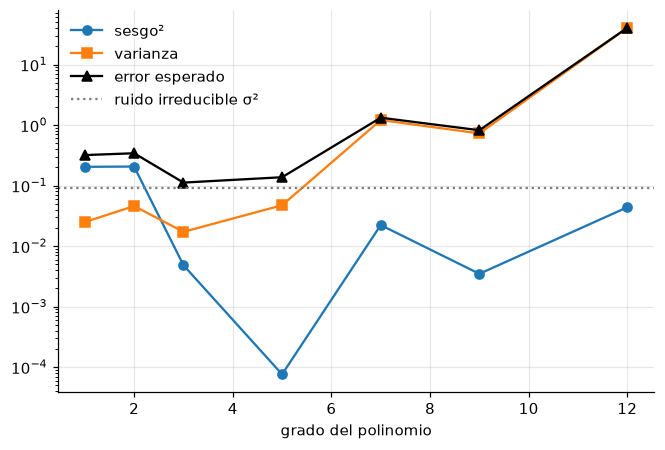

In [2]:
def f_true(x):
    return np.sin(2 * np.pi * x)


x_grid = np.linspace(0, 1, 100)[:, None]
sigma, n, reps = 0.3, 30, 200
degrees = [1, 2, 3, 5, 7, 9, 12]
bias2, var = [], []
for d in degrees:
    preds = np.empty((reps, len(x_grid)))
    for r in range(reps):
        x = rng.random((n, 1))
        y = f_true(x[:, 0]) + rng.normal(0, sigma, n)
        model = make_pipeline(PolynomialFeatures(d), LinearRegression()).fit(x, y)
        preds[r] = model.predict(x_grid)
    bias2.append(np.mean((preds.mean(0) - f_true(x_grid[:, 0])) ** 2))
    var.append(np.mean(preds.var(0)))

fig, ax = plt.subplots()
ax.plot(degrees, bias2, "o-", label="sesgo²")
ax.plot(degrees, var, "s-", label="varianza")
ax.plot(degrees, np.array(bias2) + np.array(var) + sigma**2, "k^-", label="error esperado")
ax.axhline(sigma**2, color="gray", ls=":", label="ruido irreducible σ²")
ax.set_yscale("log")
ax.set_xlabel("grado del polinomio")
ax.legend();

## 2. ¿Cuánto varía la estimación?

Un *holdout* único depende de qué filas cayeron en test. Repetimos 100 particiones distintas.

In [3]:
X, y = load_breast_cancer(return_X_y=True)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
holdout = []
for i in range(100):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=i)
    holdout.append(pipe.fit(Xa, ya).score(Xb, yb))
kfold = [
    cross_val_score(pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=i)).mean()
    for i in range(100)
]
print(f"holdout 80/20:   media {np.mean(holdout):.4f}, desv. {np.std(holdout):.4f}")
print(f"5-fold (media):  media {np.mean(kfold):.4f}, desv. {np.std(kfold):.4f}")

holdout 80/20:   media 0.9776, desv. 0.0138
5-fold (media):  media 0.9769, desv. 0.0034


Promediar 5 folds reduce la varianza de la estimación (aunque los folds no son independientes).

## 3. Fuga clásica: seleccionar features con todos los datos

Experimento de *Elements of Statistical Learning* (§7.10.2): 50 muestras, 5000 features de
**ruido puro**, etiquetas al azar. Ningún modelo puede superar el 50 %.

In [4]:
Xn = rng.normal(size=(50, 5000))
yn = rng.integers(0, 2, 50)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

# MAL: elegir las 100 features más correlacionadas mirando TODAS las etiquetas, luego validar
top = SelectKBest(f_classif, k=100).fit(Xn, yn).get_support()
wrong = cross_val_score(LogisticRegression(max_iter=1000), Xn[:, top], yn, cv=cv).mean()

# BIEN: la selección vive dentro del pipeline y se reajusta en cada fold de entrenamiento
right_pipe = make_pipeline(SelectKBest(f_classif, k=100), LogisticRegression(max_iter=1000))
right = cross_val_score(right_pipe, Xn, yn, cv=cv).mean()
print(f"selección fuera del CV: {wrong:.2f}   ← espejismo")
print(f"selección dentro del CV: {right:.2f}   ← la verdad: azar")

selección fuera del CV: 1.00   ← espejismo
selección dentro del CV: 0.36   ← la verdad: azar


Que salga *por debajo* de 0.5 no es un error: con 50 muestras de ruido puro la estimación
por CV tiene mucha varianza, y además un sesgo negativo conocido (al sacar un fold, la clase
mayoritaria del entrenamiento tiende a ser la minoritaria del test).

La regla: **todo lo que aprende de los datos** (escalar, imputar, seleccionar, codificar)
va dentro del `Pipeline`. Por eso `applied_ml.model_selection.cross_validate` clona el
estimador completo en cada fold.

## 4. Optimismo de selección: el mejor de muchos

Elegir la mejor de muchas configuraciones con el mismo CV y reportar ese puntaje es elegir
el máximo de estimaciones ruidosas: está sesgado hacia arriba. La CV **anidada** lo corrige
evaluando la configuración elegida en datos que la búsqueda no vio.

In [5]:
Xs, ys = load_breast_cancer(return_X_y=True)
idx = rng.choice(len(ys), 120, replace=False)  # pocos datos: estimaciones ruidosas
Xs, ys = Xs[idx], ys[idx]
grid = {"logisticregression__C": np.logspace(-4, 4, 40)}
inner = StratifiedKFold(3, shuffle=True, random_state=1)
outer = StratifiedKFold(5, shuffle=True, random_state=2)
base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
search = GridSearchCV(base, grid, cv=inner)

naive = search.fit(Xs, ys).best_score_
nested = cross_val_score(search, Xs, ys, cv=outer).mean()
print(f"mejor puntaje de la búsqueda (ingenuo): {naive:.4f}")
print(f"CV anidada:                             {nested:.4f}")

mejor puntaje de la búsqueda (ingenuo): 0.9917
CV anidada:                             0.9750


El sesgo crece con el tamaño de la grilla y con el ruido de cada estimación (pocos datos).
En el proyecto (32 000 filas, grillas de ≤ 6 configuraciones) resultó despreciable: allí el
puntaje interno quedó incluso *por debajo* del externo, porque la búsqueda interna entrena con
2/3 de los datos. Dos sesgos opuestos; cuál domina depende de n y del tamaño de la búsqueda.

## Para llevar

- Error = sesgo² + varianza + ruido: la complejidad mueve los dos primeros en sentidos opuestos.
- Reportar media **y** dispersión de la CV; un holdout único puede engañar.
- Todo preprocesamiento dentro del pipeline. Selección de hiperparámetros → CV anidada.